In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
import random
from keras import models,layers
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam

In [2]:
x_train=np.load("mnist.npz/x_train.npy")
y_train=np.load("mnist.npz/y_train.npy")
x_test=np.load("mnist.npz/x_test.npy")
y_test=np.load("mnist.npz/y_test.npy")

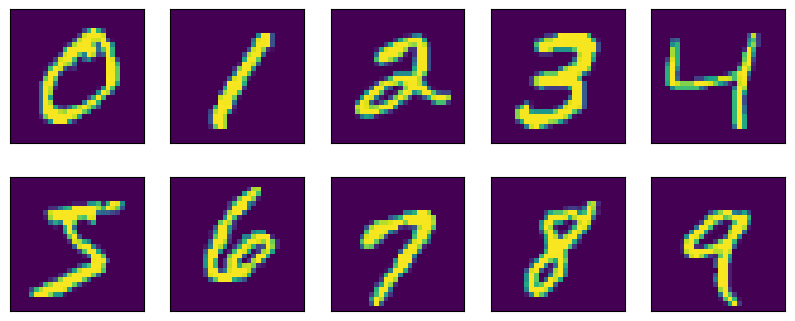

In [3]:
unique_labels = np.unique(y_train)

plt.figure(figsize=(10, 4))
for i in range(len(unique_labels)):
    idx = np.where(y_train == unique_labels[i])[0][0]
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[idx])
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
plt.show()

In [4]:
max_pixel_value = x_train.max()
x_train = x_train.astype("float32") / max_pixel_value
x_test = x_test.astype("float32") / max_pixel_value

In [5]:
model = models.Sequential([
    layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'), 
    layers.Dense(128, activation='relu'), 
    layers.Dense(64, activation='relu'),  
    layers.Dense(10, activation='softmax') 
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)
history = model.fit(
    x_train, y_train,
    epochs=50,
    validation_data=(x_test, y_test),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.9344 - loss: 0.2163 - val_accuracy: 0.9675 - val_loss: 0.1083
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.9711 - loss: 0.0930 - val_accuracy: 0.9727 - val_loss: 0.0888
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.9802 - loss: 0.0632 - val_accuracy: 0.9733 - val_loss: 0.0882
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9843 - loss: 0.0506 - val_accuracy: 0.9794 - val_loss: 0.0757
Epoch 5/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 9ms/step - accuracy: 0.9874 - loss: 0.0388 - val_accuracy: 0.9767 - val_loss: 0.0882
Epoch 6/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9889 - loss: 0.0352 - val_accuracy: 0.9767 - val_loss: 0.0946
Epoch 7/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - accuracy: 0.9904 - loss: 0.0295 - val_accuracy: 0.9784 - val_loss: 0.0874


In [7]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9794 - loss: 0.0757


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Handwritten number in the displayed image (index 4159) is: 8


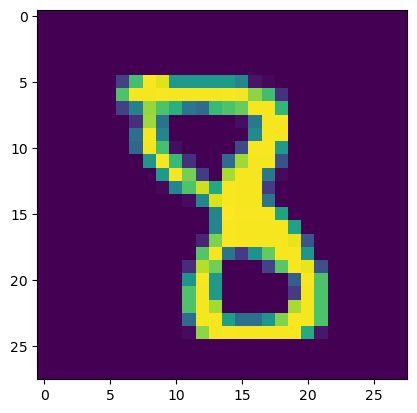

In [8]:
n = random.randint(0, len(x_test)-1)
plt.imshow(x_test[n])
predicted_values = model.predict(x_test, verbose=1)
predicted_class = np.argmax(predicted_values[n])
actual_class=y_test[n]
print(f"Handwritten number in the displayed image (index {n}) is: {predicted_class}")

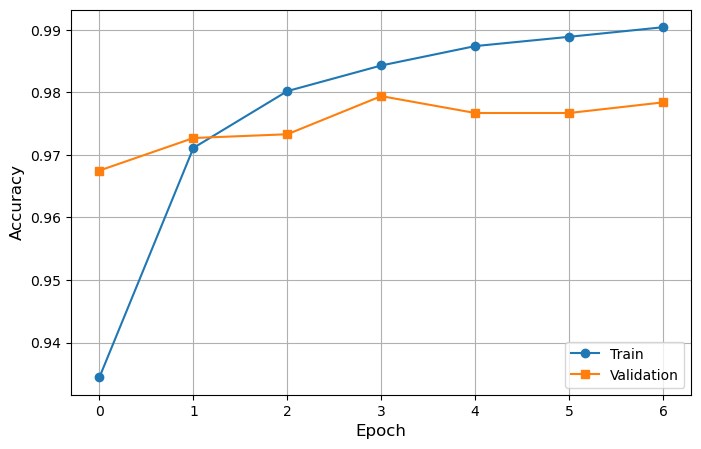

In [9]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], marker='o')
plt.plot(history.history['val_accuracy'], marker='s')
plt.ylabel('Accuracy', fontsize=12)
plt.xlabel('Epoch', fontsize=12)
plt.legend(['Train', 'Validation'], loc='lower right')
plt.grid(True)
plt.show()